# Eksplorasi & Karakterisasi Data Telemetri Lintas Domain (EDA)
## Evaluasi Kampanye Eksperimen 10 Menit per Skenario (4.500 Sampel)

**Peneliti:** Idhul Rahman  
**Afiliasi:** Program Tesis Magister — 5G O-RAN Multi-Slice Testbed  
**Berkas Dataset:** `data/telemetry_dataset_10min_complete.csv` (1.205 KB, 4.500 baris, 40 kolom)  
**Cakupan Skenario:** `S1` (Normal Light), `S2` (Normal High), `S3` (RAN Overload), `S6` (Core TBF), `S9` (Joint Overload), `S10_A` (Release RAN), `S10_B` (Release Core), `CLEAR` (Quiescent Baseline).

---

### Catatan Metodologi & Batasan Observasi Pengamat:
1. **Bukan 4.500 Detik Kontinu:** Dataset ini terdiri dari **8 run eksperimen independen** (7 run berdurasi 600 detik + 1 run CLEAR 300 detik). Terdapat jeda waktu nyata antar-run (misal: ~50,35 detik antara S9 dan S10_A; ~49,87 detik antara S10_A dan S10_B). Visualisasi runtun waktu harus mempertahankan atau menampilkan jeda ini secara jujur.
2. **Status Fitur NWDAF:** Fitur native 3GPP `nwdaf_comm_*` dan `nwdaf_load_*` seluruhnya bernilai `NaN` dengan `nwdaf_api_status = 0`. Fitur kernel qdisc UPF (`upf_backlog_bytes_embb` dan `upf_drops_embb`) dianalisis sebagai referensi/audit observabilitas host (Track 2 OAM), bukan substitusi diam-diam bagi analitik NWDAF.
3. **Transien Pemulihan Core:** Pada S10_B, sampel pertama langsung mencatat backlog 0 B karena TBF dicabut saat jeda transisi antar-run. Data ini menangkap kondisi pasca-pemulihan, bukan proses pengurasan buffer (*draining*) seketika.
4. **Pengujian Keterpisahan Fitur:** EDA ini bertujuan menguji secara empiris keterpisahan fitur antar domain gangguan, bukan mengasumsikannya secara apriori.


In [1]:
# 1. Import library analisis data dan visualisasi ilmiah
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi gaya visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['figure.dpi'] = 120

DATASET_PATH = os.path.join('..', 'data', 'telemetry_dataset_10min_complete.csv')
if not os.path.exists(DATASET_PATH):
    DATASET_PATH = os.path.join('data', 'telemetry_dataset_10min_complete.csv')

print('Memuat dataset dari:', os.path.abspath(DATASET_PATH))
df = pd.read_csv(DATASET_PATH)
print('Dimensi Dataset:', df.shape[0], 'baris x', df.shape[1], 'kolom')


Memuat dataset dari: D:\Idhul\Program\Thesis\data\telemetry_dataset_10min_complete.csv
Dimensi Dataset: 4500 baris x 40 kolom


## 1. Taksonomi & Demarkasi Kolom Telemetri

Untuk memastikan keabsahan metodologi dan mencegah kebocoran informasi (*data leakage*):
- Kolom **Metadata/Identifier** dan **Keluaran Diagnosa rApp** dieksklusi dari input model.
- Kolom **Ground Truth SLA/Probe** (`e2e_slice*`) berfungsi sebagai pemantau validasi dan penilai dampak layanan, bukan prediktor kemacetan.
- Kolom **Infrastruktur Fisik** (RAN scheduler & UPF kernel qdisc) adalah kandidat utama fitur prediktor diagnostik.


In [2]:
# Taksonomi kolom resmi sesuai Metric Catalog dan Demarkasi Penelitian
METADATA_COLS = [
    'timestamp_utc', 'elapsed_sec', 'run_id', 'scrape_ok', 'scrape_latency_ms',
    'event_phase_id', 'event_scenario', 'event_domain', 'event_component',
    'rapp_diagnosed_bottleneck', 'rapp_confidence'
]

SLA_PROBE_COLS = [
    'e2e_slice1_tput_mbps', 'e2e_slice1_jitter_ms', 'e2e_slice1_rtt_ms', 'e2e_slice1_loss_pct',
    'e2e_slice2_rtt_ms', 'e2e_slice2_loss_pct', 'e2e_probe_freshness'
]

INFRA_RAN_COLS = [
    'ran_prb_cell1', 'ran_prb_cell2', 'ran_mcs_cell1', 'ran_mcs_cell2',
    'ran_bler_cell1', 'ran_bler_cell2', 'ran_snr_cell1', 'ran_snr_cell2'
]

INFRA_CORE_COLS = [
    'estimated_load_embb', 'estimated_load_urllc',
    'upf_backlog_bytes_embb', 'upf_backlog_bytes_urllc',
    'upf_drops_embb', 'upf_drops_urllc'
]

NWDAF_COLS = [
    'nwdaf_load_embb', 'nwdaf_load_urllc', 'nwdaf_comm_ul_bytes', 'nwdaf_comm_dl_bytes',
    'nwdaf_comm_duration_sec', 'nwdaf_comm_vol_std_bytes', 'nwdaf_comm_freshness', 'nwdaf_api_status'
]

classified_total = len(METADATA_COLS) + len(SLA_PROBE_COLS) + len(INFRA_RAN_COLS) + len(INFRA_CORE_COLS) + len(NWDAF_COLS)
print('Total Kolom Terklasifikasi:', classified_total, '/', df.shape[1])


Total Kolom Terklasifikasi: 40 / 40


## 2. Audit Kualitas Data: Kelengkapan, Nilai Hilang, & Fitur Konstan

Sesuai arahan pengamat, evaluasi kelengkapan data harus mengidentifikasi:
1. Fitur yang **100% NaN** (tidak terisi data numerik sama sekali).
2. Fitur yang **Konstan** (varians nol), sehingga tidak memberikan informasi diferensiasi bagi klasifikasi.
3. Sifat fisik nilai `NaN` pada metrik RTT eMBB (`e2e_slice1_rtt_ms`).


In [3]:
# Perhitungan kelengkapan dan variansi per kolom
audit_rows = []
for col in df.columns:
    total_count = len(df[col])
    nan_count = int(df[col].isnull().sum())
    valid_count = total_count - nan_count
    pct_valid = round((valid_count / total_count) * 100.0, 1)
    
    is_numeric = pd.api.types.is_numeric_dtype(df[col])
    num_unique = df[col].nunique(dropna=True)
    is_constant = (num_unique <= 1)
    
    val_min = round(float(df[col].min()), 2) if is_numeric and valid_count > 0 else 'N/A'
    val_max = round(float(df[col].max()), 2) if is_numeric and valid_count > 0 else 'N/A'
    
    audit_rows.append({
        'Kolom': col,
        'Tipe': 'Numeric' if is_numeric else 'String',
        'Valid': valid_count,
        'NaN': nan_count,
        '% Valid': str(pct_valid) + '%',
        'Unique': num_unique,
        'Status Variasi': '100% NaN' if valid_count == 0 else ('Konstan' if is_constant else 'Bervariasi'),
        'Min': str(val_min),
        'Max': str(val_max)
    })

df_audit = pd.DataFrame(audit_rows)
pd.set_option('display.max_rows', 45)
display(df_audit)

cols_all_nan = df_audit[df_audit['Status Variasi'] == '100% NaN']['Kolom'].tolist()
cols_constant = df_audit[df_audit['Status Variasi'] == 'Konstan']['Kolom'].tolist()

print('\n--- KESIMPULAN AUDIT INTEGRITAS FITUR ---')
print('Kolom 100% NaN (' + str(len(cols_all_nan)) + ' kolom):', cols_all_nan)
print('Kolom Konstan / Varians Nol (' + str(len(cols_constant)) + ' kolom):', cols_constant)



--- KESIMPULAN AUDIT INTEGRITAS FITUR ---
Kolom 100% NaN (7 kolom): ['e2e_slice1_jitter_ms', 'nwdaf_load_embb', 'nwdaf_load_urllc', 'nwdaf_comm_ul_bytes', 'nwdaf_comm_dl_bytes', 'nwdaf_comm_duration_sec', 'nwdaf_comm_vol_std_bytes']
Kolom Konstan / Varians Nol (12 kolom): ['scrape_ok', 'e2e_probe_freshness', 'nwdaf_comm_freshness', 'nwdaf_api_status', 'upf_backlog_bytes_urllc', 'upf_drops_urllc', 'ran_prb_cell2', 'ran_mcs_cell1', 'ran_bler_cell1', 'ran_bler_cell2', 'rapp_diagnosed_bottleneck', 'rapp_confidence']


,Kolom,Tipe,Valid,NaN,% Valid,Unique,Status Variasi,Min,Max
0,timestamp_utc,String,4500,0,100.0%,4500,Bervariasi,N/A,N/A
1,elapsed_sec,Numeric,4500,0,100.0%,4409,Bervariasi,0.0,599.0
2,run_id,String,4500,0,100.0%,8,Bervariasi,N/A,N/A
3,scrape_ok,Numeric,4500,0,100.0%,1,Konstan,1.0,1.0
4,scrape_latency_ms,Numeric,4500,0,100.0%,1319,Bervariasi,1.37,8.23
5,e2e_slice1_tput_mbps,Numeric,4500,0,100.0%,40,Bervariasi,9.87,81.4
6,e2e_slice1_jitter_ms,Numeric,0,4500,0.0%,0,100% NaN,N/A,N/A
7,e2e_slice1_rtt_ms,Numeric,3300,1200,73.3%,339,Bervariasi,8.38,448.0
8,e2e_slice1_loss_pct,Numeric,4500,0,100.0%,10,Bervariasi,0.0,100.0
9,e2e_slice2_rtt_ms,Numeric,4500,0,100.0%,323,Bervariasi,7.93,145.0


## 3. Rincian Kelengkapan Data & Status NWDAF per Run Eksperimen

Berikut adalah rincian statistik kelengkapan data pada masing-masing dari ke-8 run eksperimen mandiri.


In [4]:
run_summary = []
for run_id, grp in df.groupby('run_id', sort=False):
    scen = grp['event_scenario'].iloc[0]
    dom = grp['event_domain'].iloc[0]
    n_rows = len(grp)
    scrape_ok_pct = round((grp['scrape_ok'].sum() / n_rows) * 100.0, 1)
    
    s1_outage_pct = round((grp['e2e_slice1_rtt_ms'].isnull().sum() / n_rows) * 100.0, 1)
    s2_rtt_mean = round(float(grp['e2e_slice2_rtt_ms'].mean()), 2)
    s2_loss_mean = round(float(grp['e2e_slice2_loss_pct'].mean()), 1)
    
    prb_c1_mean = round(float(grp['ran_prb_cell1'].mean()), 1)
    backlog_max = int(grp['upf_backlog_bytes_embb'].max())
    drops_total = int(grp['upf_drops_embb'].sum())
    nwdaf_status = int(grp['nwdaf_api_status'].mean())
    
    run_summary.append({
        'Run ID': run_id,
        'Skenario': scen,
        'Domain': dom,
        'Sampel': n_rows,
        'Scrape OK': str(scrape_ok_pct) + '%',
        'eMBB Outage': str(s1_outage_pct) + '%',
        'URLLC RTT Avg (ms)': s2_rtt_mean,
        'URLLC Loss (%)': str(s2_loss_mean) + '%',
        'PRB C1 Avg (%)': str(prb_c1_mean) + '%',
        'Backlog Max (B)': f'{backlog_max:,}',
        'NWDAF API Status': nwdaf_status
    })

df_run_summary = pd.DataFrame(run_summary)
display(df_run_summary)


,Run ID,Skenario,Domain,Sampel,Scrape OK,eMBB Outage,URLLC RTT Avg (ms),URLLC Loss (%),PRB C1 Avg (%),Backlog Max (B),NWDAF API Status
0,EXP_S1_20261019_152747,S1_NORMAL_LIGHT,BASELINE,600,100.0%,0.0%,27.32,0.0%,62.3%,0,0
1,EXP_S2_20261019_155025,S2_NORMAL_HIGH,BASELINE,600,100.0%,0.0%,26.87,0.0%,77.2%,0,0
2,EXP_S3_20261019_170042,S3_RAN_OVERLOAD,RAN,600,100.0%,100.0%,28.80,7.2%,100.0%,0,0
3,EXP_S6_20261019_171407,S6_CORE_QUEUE_TBF,CORE,600,100.0%,0.0%,23.18,0.0%,73.0%,"310,234",0
4,EXP_S9_20261019_173912,S9_JOINT_OVERLOAD,JOINT,600,100.0%,100.0%,28.64,6.1%,100.0%,"310,218",0
5,EXP_S10_A_20261019_175002,S10_A_RELEASE_RAN,CORE,600,100.0%,0.0%,27.47,0.0%,81.5%,"310,234",0
6,EXP_S10_B_20261019_180051,S10_B_RELEASE_CORE,BASELINE,600,100.0%,0.0%,26.75,0.0%,80.0%,0,0
7,EXP_CLEAR_20261019_181159,CLEAR_FAULT,BASELINE,300,100.0%,0.0%,25.15,0.0%,65.3%,0,0


## 4. Visualisasi Runtun Waktu Berurutan dengan Batas Run Nyata

Sesuai arahan pengamat, kita tidak boleh menyambungkan batas run seolah-olah terjadi 4.500 detik kontinu tanpa henti. Di bawah ini disajikan visualisasi runtun waktu per skenario secara bersekat (*per-run panels / demarcated sequence*) untuk memperlihatkan jeda waktu dan dinamika transien masing-masing pengujian.


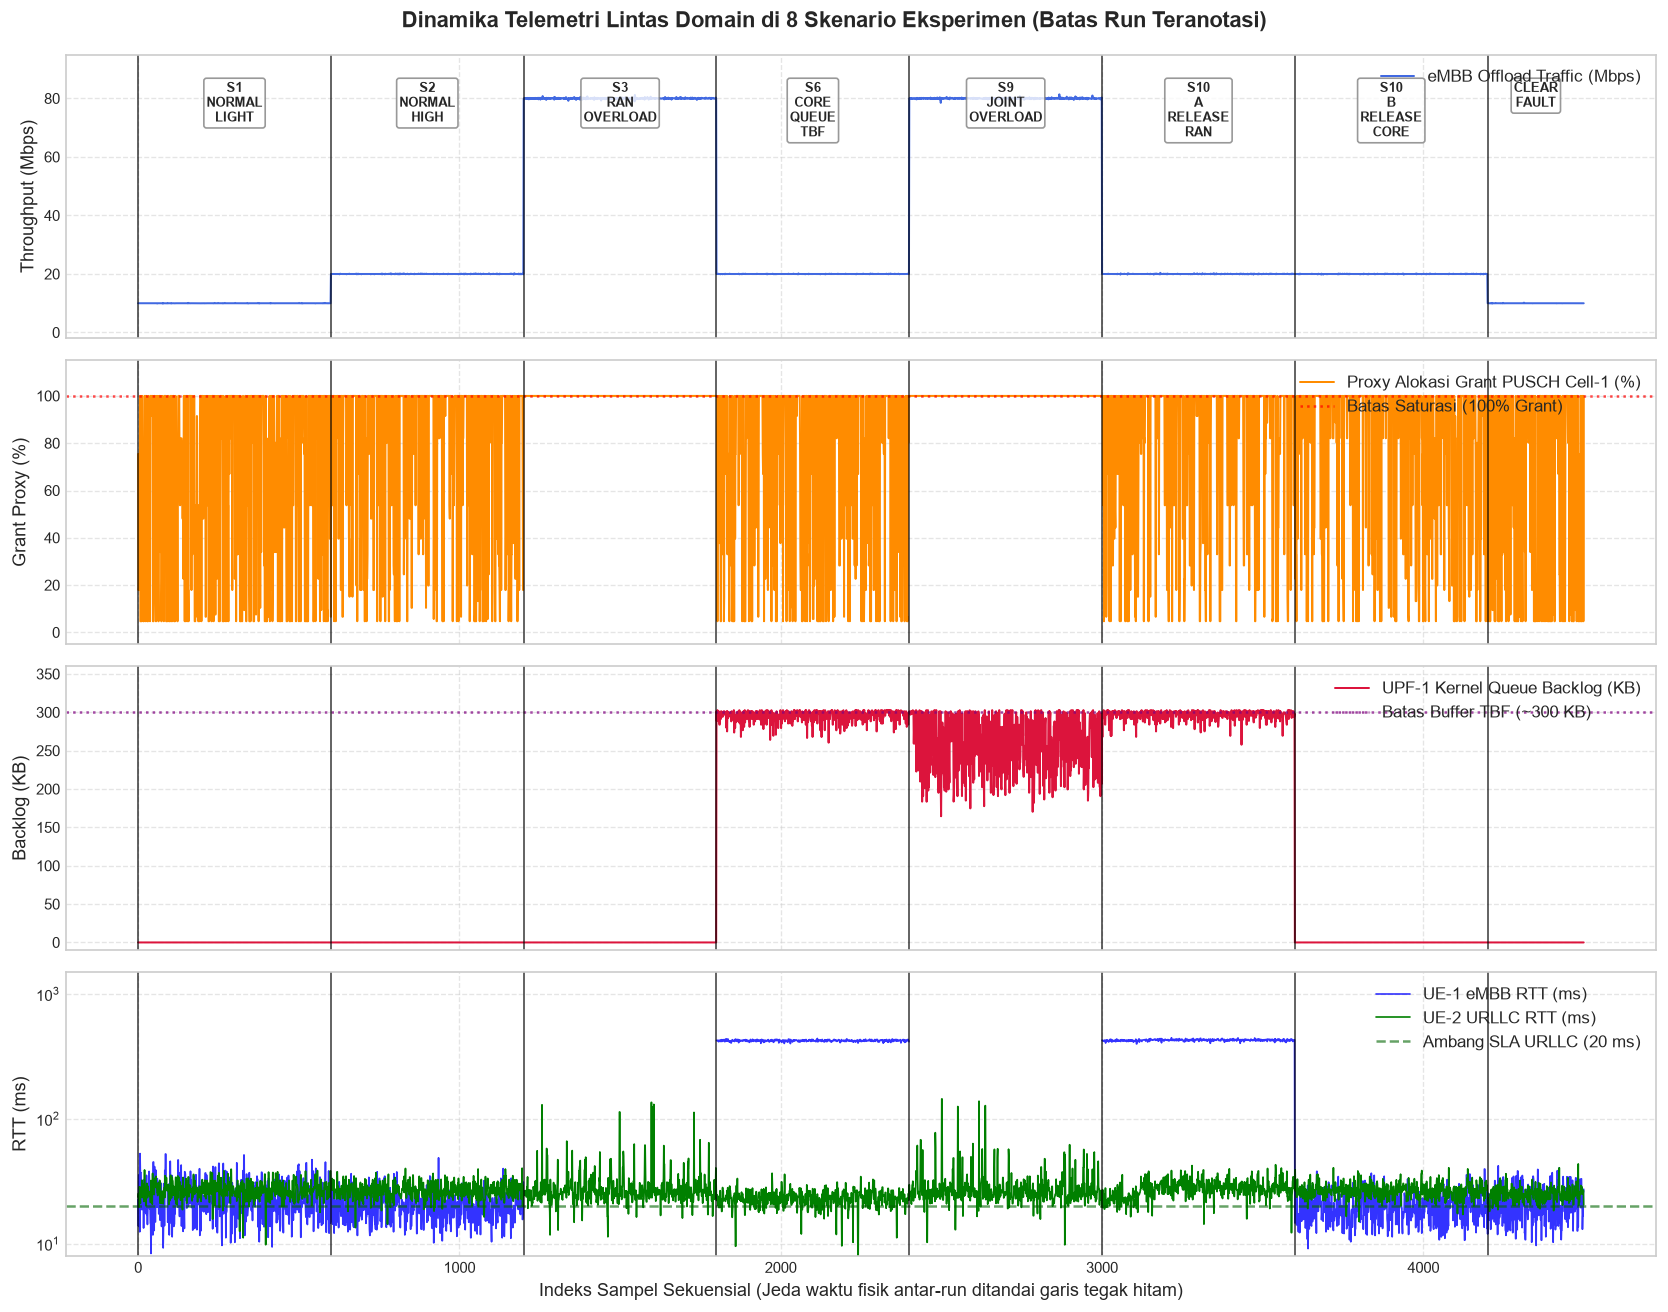

In [5]:
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)
x_indices = np.arange(len(df))

# 1. Throughput eMBB
axes[0].plot(x_indices, df['e2e_slice1_tput_mbps'], color='royalblue', lw=1.2, label='eMBB Offload Traffic (Mbps)')
axes[0].set_ylabel('Throughput (Mbps)')
axes[0].set_ylim(-2, 95)
axes[0].grid(True, ls='--', alpha=0.5)
axes[0].legend(loc='upper right')

# 2. Proxy Alokasi Grant PUSCH (ran_prb_cell1)
axes[1].plot(x_indices, df['ran_prb_cell1'], color='darkorange', lw=1.2, label='Proxy Alokasi Grant PUSCH Cell-1 (%)')
axes[1].axhline(100.0, color='red', ls=':', alpha=0.7, label='Batas Saturasi (100% Grant)')
axes[1].set_ylabel('Grant Proxy (%)')
axes[1].set_ylim(-5, 115)
axes[1].grid(True, ls='--', alpha=0.5)
axes[1].legend(loc='upper right')

# 3. Kedalaman Antrean UPF (Backlog Bytes)
axes[2].plot(x_indices, df['upf_backlog_bytes_embb'] / 1024.0, color='crimson', lw=1.2, label='UPF-1 Kernel Queue Backlog (KB)')
axes[2].axhline(300.0, color='purple', ls=':', alpha=0.7, label='Batas Buffer TBF (~300 KB)')
axes[2].set_ylabel('Backlog (KB)')
axes[2].set_ylim(-10, 360)
axes[2].grid(True, ls='--', alpha=0.5)
axes[2].legend(loc='upper right')

# 4. Latensi Canary RTT UE-1 & UE-2
axes[3].plot(x_indices, df['e2e_slice1_rtt_ms'], color='blue', lw=1.0, alpha=0.8, label='UE-1 eMBB RTT (ms)')
axes[3].plot(x_indices, df['e2e_slice2_rtt_ms'], color='green', lw=1.0, label='UE-2 URLLC RTT (ms)')
axes[3].axhline(20.0, color='darkgreen', ls='--', alpha=0.6, label='Ambang SLA URLLC (20 ms)')
axes[3].set_ylabel('RTT (ms)')
axes[3].set_yscale('log')
axes[3].set_ylim(8, 1500)
axes[3].grid(True, ls='--', alpha=0.5)
axes[3].legend(loc='upper right')

# Batas antar-run
current_idx = 0
for run_id, grp in df.groupby('run_id', sort=False):
    scen = grp['event_scenario'].iloc[0]
    mid_point = current_idx + len(grp) / 2
    for ax in axes:
        ax.axvline(current_idx, color='black', ls='-', lw=1.2, alpha=0.6)
    label_clean = scen.replace('_', '\n')
    axes[0].text(mid_point, 86, label_clean, ha='center', va='top', fontsize=8, fontweight='bold',
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='gray'))
    current_idx += len(grp)

axes[3].set_xlabel('Indeks Sampel Sekuensial (Jeda waktu fisik antar-run ditandai garis tegak hitam)')
plt.suptitle('Dinamika Telemetri Lintas Domain di 8 Skenario Eksperimen (Batas Run Teranotasi)', y=0.99, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 5. Evaluasi Pasangan Terkendali (*Controlled Pair Analysis*)

### A. Pasangan S2 (Normal High) vs. S6 (Core TBF Bottleneck)
Kedua skenario diberi beban trafik yang sama persis (~20 Mbps). Perbedaan perlakuan satu-satunya adalah penerapan pembatas antrean Linux TBF 12 Mbps / 200 ms pada UPF-1 di S6.

### B. Analisis Rangkaian Pemulihan Bertahap (S9 $\to$ S10_A $\to$ S10_B)
- **S9 (Joint Overload):** Beban 80M + Core TBF 12M.
- **S10_A (Release RAN):** Beban radio diturunkan ke 20M, Core TBF tetap aktif.
- **S10_B (Release Core):** Core TBF dicabut, beban tetap 20M. *(Catatan pengamat: Sampel pertama S10_B sudah 0 B karena TBF dicabut saat jeda transisi ~49,87 detik)*.


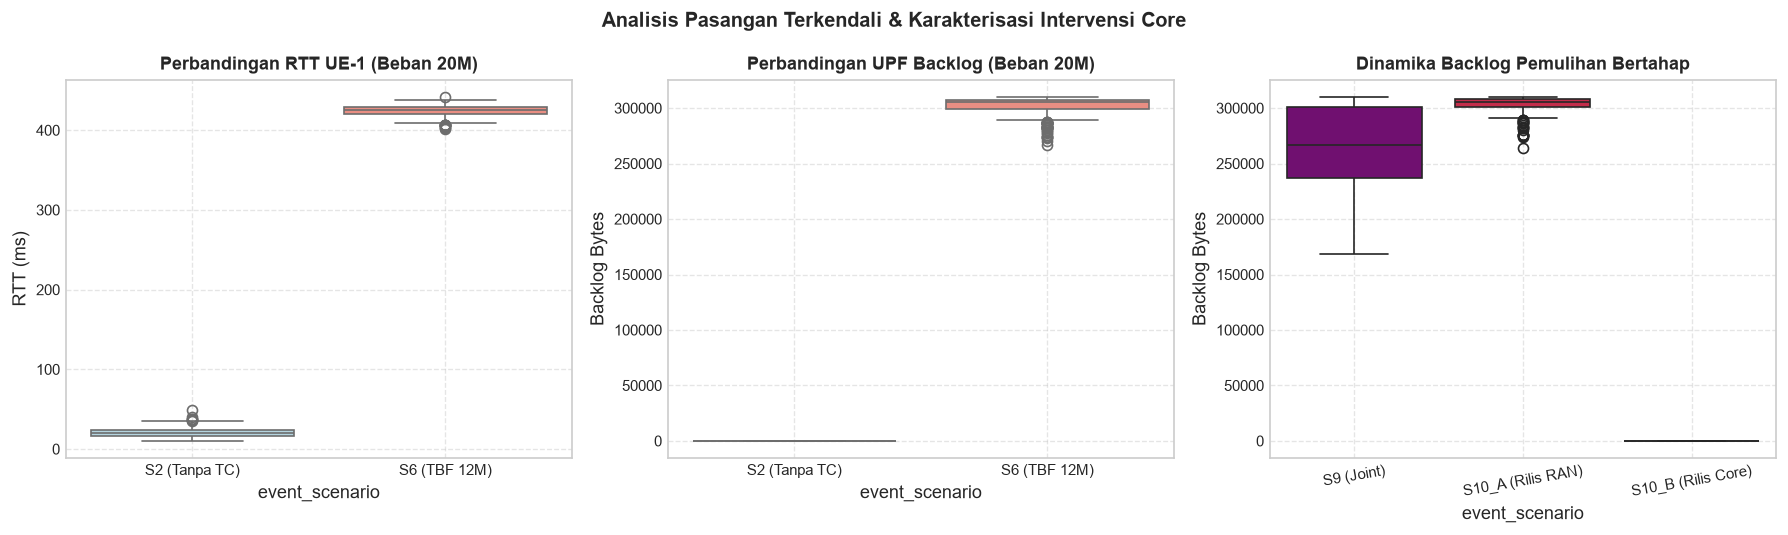

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. Perbandingan RTT UE-1 pada S2 vs S6
df_s2_s6 = df[df['event_scenario'].isin(['S2_NORMAL_HIGH', 'S6_CORE_QUEUE_TBF'])].copy()
sns.boxplot(data=df_s2_s6, x='event_scenario', y='e2e_slice1_rtt_ms', ax=axes[0], palette=['lightblue', 'salmon'])
axes[0].set_title('Perbandingan RTT UE-1 (Beban 20M)', fontweight='bold')
axes[0].set_ylabel('RTT (ms)')
axes[0].set_xticklabels(['S2 (Tanpa TC)', 'S6 (TBF 12M)'])
axes[0].grid(True, ls='--', alpha=0.5)

# 2. Perbandingan UPF Backlog pada S2 vs S6
sns.boxplot(data=df_s2_s6, x='event_scenario', y='upf_backlog_bytes_embb', ax=axes[1], palette=['lightblue', 'salmon'])
axes[1].set_title('Perbandingan UPF Backlog (Beban 20M)', fontweight='bold')
axes[1].set_ylabel('Backlog Bytes')
axes[1].set_xticklabels(['S2 (Tanpa TC)', 'S6 (TBF 12M)'])
axes[1].grid(True, ls='--', alpha=0.5)

# 3. Rangkaian Staged Recovery: S9 -> S10_A -> S10_B
df_rec = df[df['event_scenario'].isin(['S9_JOINT_OVERLOAD', 'S10_A_RELEASE_RAN', 'S10_B_RELEASE_CORE'])].copy()
rec_order = ['S9_JOINT_OVERLOAD', 'S10_A_RELEASE_RAN', 'S10_B_RELEASE_CORE']
sns.boxplot(data=df_rec, x='event_scenario', y='upf_backlog_bytes_embb', order=rec_order, ax=axes[2], palette=['purple', 'crimson', 'lightgreen'])
axes[2].set_title('Dinamika Backlog Pemulihan Bertahap', fontweight='bold')
axes[2].set_ylabel('Backlog Bytes')
axes[2].set_xticklabels(['S9 (Joint)', 'S10_A (Rilis RAN)', 'S10_B (Rilis Core)'], rotation=10)
axes[2].grid(True, ls='--', alpha=0.5)

plt.suptitle('Analisis Pasangan Terkendali & Karakterisasi Intervensi Core', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## 6. Uji Keterpisahan Fitur Antar Domain Gangguan (*Feature Separability*)

Sesuai arahan pengamat: **kita menggunakan EDA untuk menguji apakah fitur terpisah secara empiris, bukan mengasumsikan sejak awal bahwa keterpisahannya pasti tegas.**

Kita menguji 2 fitur utama yang diusulkan sebagai pembeda domain:
1. `ran_prb_cell1` (Proxy alokasi grant PUSCH Cell-1)
2. `upf_backlog_bytes_embb` (Kedalaman antrean kernel qdisc UPF-1)

Terhadap 4 target kelas domain: `BASELINE`, `RAN`, `CORE`, dan `JOINT`.


=== TEMUAN KETERPISAHAN FITUR SECARA EMPIRIS ===
1. ran_prb_cell1: Kelas RAN dan JOINT keduanya mengalami saturasi pada ~100%, sehingga PRB saja TIDAK BISA membedakan RAN dari JOINT.
2. upf_backlog_bytes_embb: Kelas CORE dan JOINT keduanya menunjukkan antrean jenuh (~310 KB), sehingga Backlog saja TIDAK BISA membedakan CORE dari JOINT.
3. KESIMPULAN: Diperlukan kombinasi simultan (vektor lintas domain [PRB, Backlog]) untuk mendiagnosis keempat kelas secara unik!


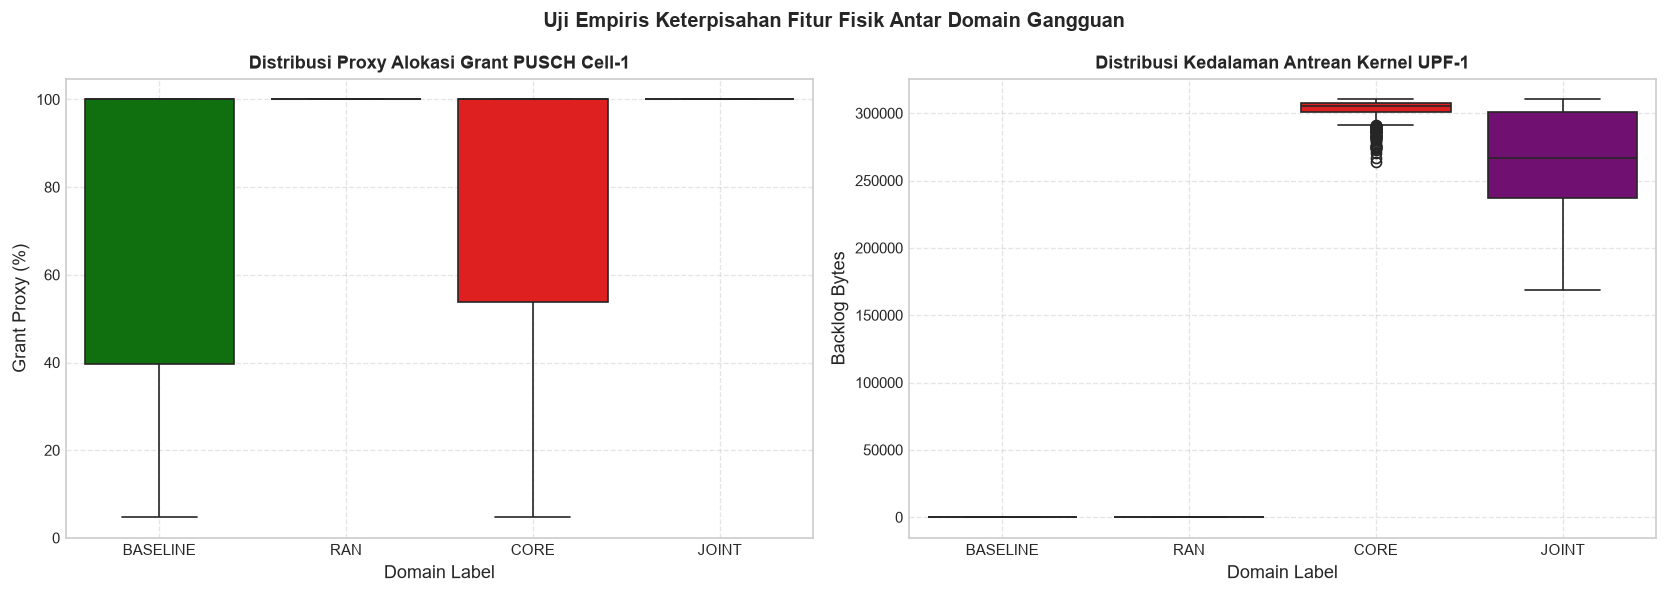

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
domain_order = ['BASELINE', 'RAN', 'CORE', 'JOINT']
palette = {'BASELINE': 'green', 'RAN': 'orange', 'CORE': 'red', 'JOINT': 'purple'}

# 1. Distribusi PRB C1 per Domain
sns.boxplot(data=df, x='event_domain', y='ran_prb_cell1', order=domain_order, ax=axes[0], palette=palette)
axes[0].set_title('Distribusi Proxy Alokasi Grant PUSCH Cell-1', fontweight='bold')
axes[0].set_xlabel('Domain Label')
axes[0].set_ylabel('Grant Proxy (%)')
axes[0].grid(True, ls='--', alpha=0.5)

# 2. Distribusi UPF Backlog per Domain
sns.boxplot(data=df, x='event_domain', y='upf_backlog_bytes_embb', order=domain_order, ax=axes[1], palette=palette)
axes[1].set_title('Distribusi Kedalaman Antrean Kernel UPF-1', fontweight='bold')
axes[1].set_xlabel('Domain Label')
axes[1].set_ylabel('Backlog Bytes')
axes[1].grid(True, ls='--', alpha=0.5)

plt.suptitle('Uji Empiris Keterpisahan Fitur Fisik Antar Domain Gangguan', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print('=== TEMUAN KETERPISAHAN FITUR SECARA EMPIRIS ===')
print('1. ran_prb_cell1: Kelas RAN dan JOINT keduanya mengalami saturasi pada ~100%, sehingga PRB saja TIDAK BISA membedakan RAN dari JOINT.')
print('2. upf_backlog_bytes_embb: Kelas CORE dan JOINT keduanya menunjukkan antrean jenuh (~310 KB), sehingga Backlog saja TIDAK BISA membedakan CORE dari JOINT.')
print('3. KESIMPULAN: Diperlukan kombinasi simultan (vektor lintas domain [PRB, Backlog]) untuk mendiagnosis keempat kelas secara unik!')


## 7. Analisis Korelasi Lintas Domain: Global vs. Per Skenario

Sesuai arahan pengamat:
- Kolom konstan (varians nol) dan kolom yang 100% NaN **dieksklusi terlebih dahulu** sebelum menghitung korelasi.
- Jangan mengubah korelasi yang tidak terdefinisi (`NaN`) menjadi nol.
- Hitung korelasi **keseluruhan** dan **di dalam skenario spesifik** (misal S2 vs S6), agar transisi antar-skenario tidak disalahartikan sebagai korelasi kausal instan.


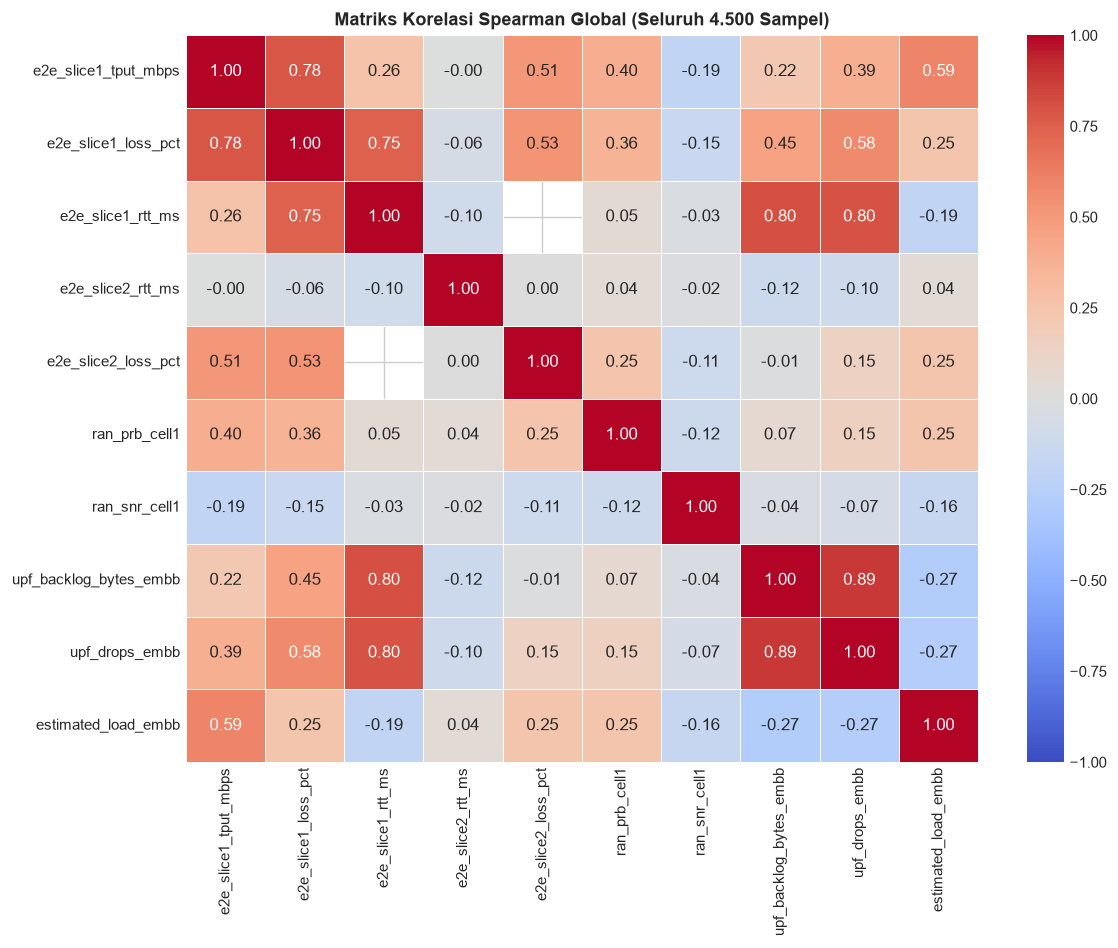

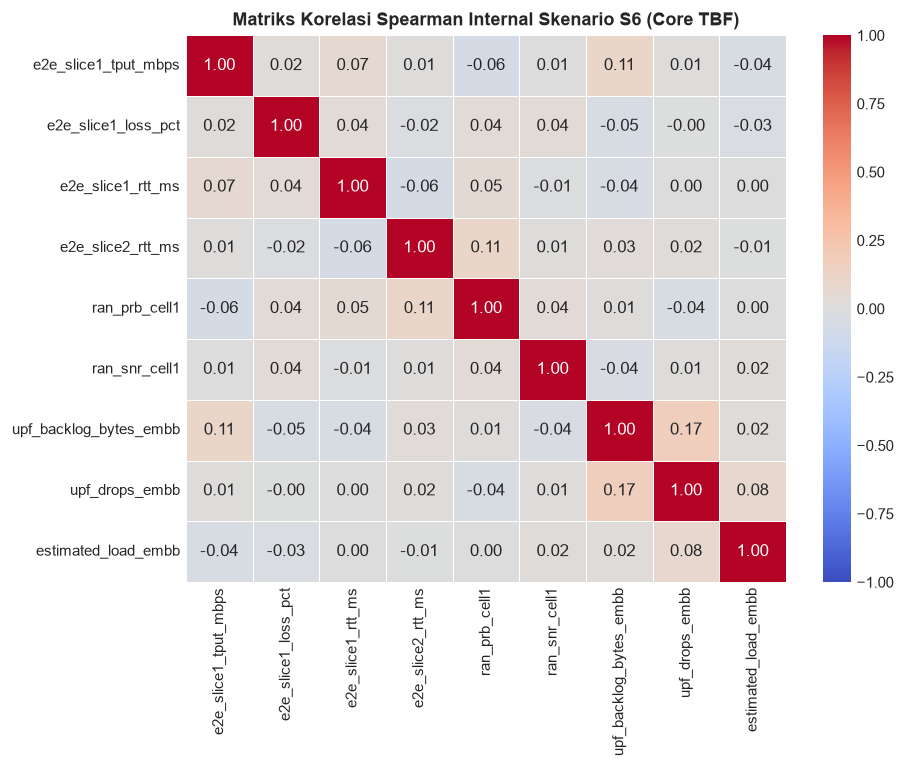

In [8]:
# Pilih fitur numerik yang memiliki variansi nyata dan bukan metadata
candidate_features = [
    'e2e_slice1_tput_mbps', 'e2e_slice1_loss_pct', 'e2e_slice1_rtt_ms',
    'e2e_slice2_rtt_ms', 'e2e_slice2_loss_pct',
    'ran_prb_cell1', 'ran_snr_cell1',
    'upf_backlog_bytes_embb', 'upf_drops_embb', 'estimated_load_embb'
]

# Hitung matriks korelasi Spearman (tahan terhadap non-linearitas antrean)
corr_global = df[candidate_features].corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(corr_global, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1.0, vmax=1.0, linewidths=0.5)
plt.title('Matriks Korelasi Spearman Global (Seluruh 4.500 Sampel)', fontweight='bold')
plt.tight_layout()
plt.show()

# Korelasi di dalam skenario Core Queue Bottleneck (S6)
df_s6 = df[df['event_scenario'] == 'S6_CORE_QUEUE_TBF'][candidate_features].dropna(axis=1, how='all')
varying_s6 = [c for c in df_s6.columns if df_s6[c].nunique() > 1]
corr_s6 = df_s6[varying_s6].corr(method='spearman')

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_s6, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1.0, vmax=1.0, linewidths=0.5)
plt.title('Matriks Korelasi Spearman Internal Skenario S6 (Core TBF)', fontweight='bold')
plt.tight_layout()
plt.show()


## 8. Rekomendasi & Implikasi Metodologi untuk Pemodelan Machine Learning

Berdasarkan audit dan temuan EDA di atas, berikut adalah keputusan metodologi resmi sebelum melangkah ke `02_compare_models.ipynb`:

### 1. Seleksi Fitur Masukan ($X$):
- **Fitur Terpilih:** `ran_prb_cell1` (proxy alokasi grant PUSCH), `ran_snr_cell1`, `upf_backlog_bytes_embb`, `upf_drops_embb`, dan `estimated_load_embb`.
- **Fitur Dieksklusi:**
  - Seluruh fitur `nwdaf_*`: 100% NaN karena keterbatasan ketersediaan endpoint upstream.
  - `ran_bler_*`, `ran_mcs_cell1`, `ran_prb_cell2`: Variansi nol (konstan).
  - `e2e_slice*`: Ground truth SLA yang tidak boleh digunakan sebagai prediktor saat inferensi tertutup.
  - Metadata identifier (`run_id`, `timestamp_utc`, `event_*`, `rapp_*`).

### 2. Penanganan Ketidakseimbangan Kelas (*Class Imbalance*):
- Distribusi kelas: `BASELINE` (46,7%), `CORE` (26,7%), `RAN` (13,3%), `JOINT` (13,3%).
- **Metodologi Pengamat:** SMOTE bukan pengganti pengulangan eksperimen independen. Penyeimbangan diutamakan menggunakan pembobotan kelas (*cost-sensitive learning* / `class_weight='balanced'`) dan metrik evaluasi utama **Macro-Averaged F1-Score** (bukan akurasi dasar).

### 3. Protokol Partisi Data & Pencegahan Kebocoran (*Leakage Prevention*):
- Standarisasi (`StandardScaler`) **wajib di-fit hanya pada data latih (Train Set)**, kemudian parameter mean dan scale tersebut digunakan untuk mentransformasikan data uji (Test Set).
- Pembagian data harus memperhatikan struktur sekuensial dan dependensi temporal run.
